# 🟢 Hierarchical (Agglomerative) Clustering — Customer Segmentation
**Dataset:** Marketing Campaign (`marketing_campaign.csv`)  
**Tujuan:** Mengelompokkan pelanggan berdasarkan perilaku pembelian menggunakan Hierarchical Agglomerative Clustering  

---
## Tahapan:
1. Load & EDA
2. Preprocessing (Missing Value)
3. Feature Engineering
4. Outlier Handling (IQR Capping)
5. Encoding Kategorik
6. Feature Scaling
7. Dendrogram — Menentukan Jumlah Cluster Optimal
8. Agglomerative Clustering
9. Evaluasi Metrik
10. Visualisasi & Cluster Profiling
11. Perbandingan dengan K-Means

## 1️⃣ Load Library & Dataset

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from datetime import datetime

# Preprocessing & Scaling
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Hierarchical Clustering
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist, squareform

# Evaluasi
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print('✅ Library berhasil di-import!')
print('📦 Versi library:')
print(f'   pandas    : {pd.__version__}')
print(f'   numpy     : {np.__version__}')
import sklearn; print(f'   sklearn   : {sklearn.__version__}')
import scipy; print(f'   scipy     : {scipy.__version__}')

✅ Library berhasil di-import!
📦 Versi library:
   pandas    : 3.0.6
   numpy     : 2.4.6
   sklearn   : 1.9.1
   scipy     : 1.17.1


In [16]:
dataset = pd.read_csv('../dataset/sentimen/marketing_campaign.csv', sep='\t')

pd.set_option('display.max_columns', None)

print(f'Shape dataset: {dataset.shape}')
print(f'Jumlah baris : {dataset.shape[0]}')
print(f'Jumlah kolom : {dataset.shape[1]}')
dataset.head()

Shape dataset: (2240, 29)
Jumlah baris : 2240
Jumlah kolom : 29


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [17]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [18]:
print('🔍 Missing Values per Kolom:')
missing = dataset.isnull().sum()
print(missing[missing > 0])
print(f'\nTotal missing values: {missing.sum()}')

🔍 Missing Values per Kolom:
Income    24
dtype: int64

Total missing values: 24


In [19]:
print('📊 Statistik Deskriptif:')
dataset.describe().round(2)

📊 Statistik Deskriptif:


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.00,2240.00,2216.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.0,2240.0,2240.00
mean,5592.16,1968.81,52247.25,0.44,0.51,49.11,303.94,26.30,166.95,37.53,27.06,44.02,2.33,4.08,2.66,5.79,5.32,0.07,0.07,0.07,0.06,0.01,0.01,3.0,11.0,0.15
std,3246.66,11.98,25173.08,0.54,0.54,28.96,336.60,39.77,225.72,54.63,41.28,52.17,1.93,2.78,2.92,3.25,2.43,0.26,0.26,0.26,0.25,0.11,0.10,0.0,0.0,0.36
min,0.00,1893.00,1730.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
25%,2828.25,1959.00,35303.00,0.00,0.00,24.00,23.75,1.00,16.00,3.00,1.00,9.00,1.00,2.00,0.00,3.00,3.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
50%,5458.50,1970.00,51381.50,0.00,0.00,49.00,173.50,8.00,67.00,12.00,8.00,24.00,2.00,4.00,2.00,5.00,6.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
75%,8427.75,1977.00,68522.00,1.00,1.00,74.00,504.25,33.00,232.00,50.00,33.00,56.00,3.00,6.00,4.00,8.00,7.00,0.00,0.00,0.00,0.00,0.00,0.00,3.0,11.0,0.00
max,11191.00,1996.00,666666.00,2.00,2.00,99.00,1493.00,199.00,1725.00,259.00,263.00,362.00,15.00,27.00,28.00,13.00,20.00,1.00,1.00,1.00,1.00,1.00,1.00,3.0,11.0,1.00


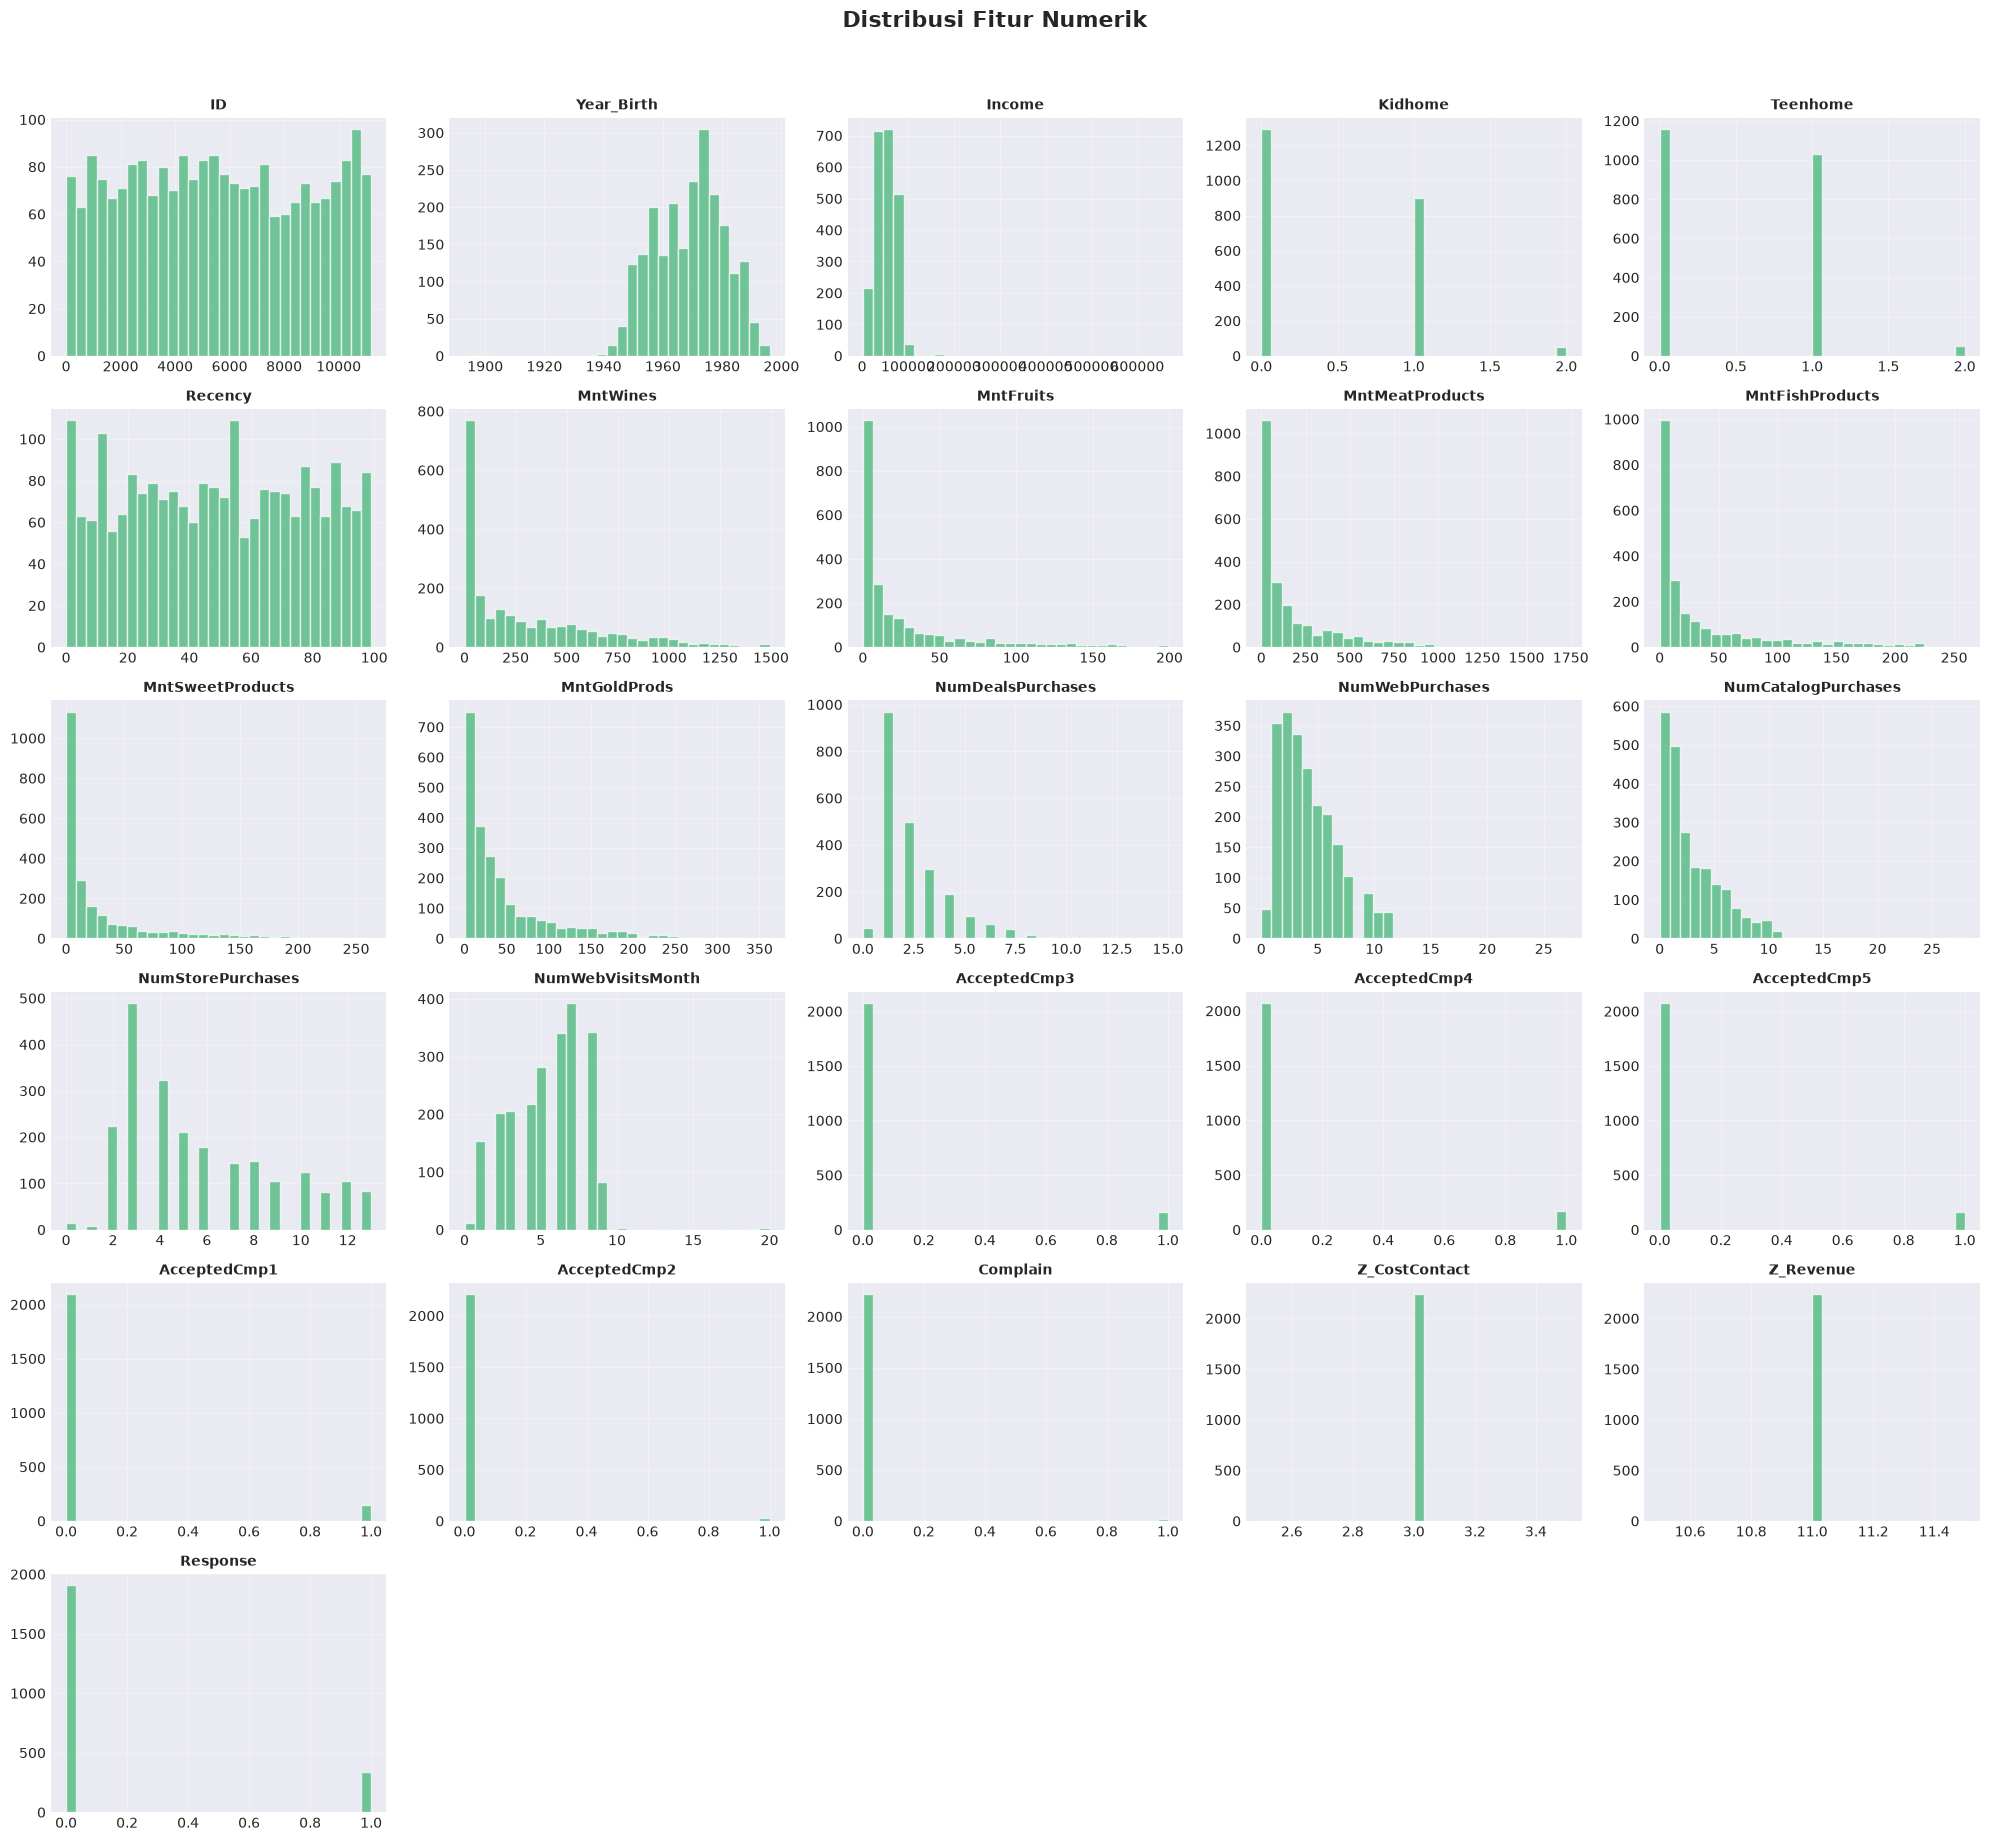

In [20]:
# Distribusi kolom numerik
num_cols = dataset.select_dtypes(include=[np.number]).columns.tolist()
n_cols = 5
n_rows = (len(num_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(dataset[col].dropna(), bins=30, color='mediumseagreen', alpha=0.7, edgecolor='white')
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribusi Fitur Numerik', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 2️⃣ Preprocessing — Handle Missing Value

In [21]:
df = dataset.copy()

# ===== HANDLE MISSING VALUES =====
# Income: 24 missing value → isi dengan MEDIAN (robust terhadap outlier)
income_median = df['Income'].median()
df['Income'].fillna(income_median, inplace=True)
print(f'✅ Income missing values diisi dengan median: {income_median:,.2f}')

# ===== DROP KOLOM TIDAK RELEVAN =====
# ID         → hanya identifier, tidak bermakna untuk clustering
# Z_CostContact & Z_Revenue → konstan (nilai selalu 3 dan 11), tidak informatif
# Response   → target/label yang tidak digunakan pada unsupervised learning
cols_to_drop = ['ID', 'Z_CostContact', 'Z_Revenue', 'Response']
df.drop(columns=cols_to_drop, inplace=True)
print(f'✅ Kolom dihapus: {cols_to_drop}')

print(f'\nShape setelah preprocessing: {df.shape}')
print(f'Total missing values tersisa: {df.isnull().sum().sum()}')

✅ Income missing values diisi dengan median: 51,381.50
✅ Kolom dihapus: ['ID', 'Z_CostContact', 'Z_Revenue', 'Response']

Shape setelah preprocessing: (2240, 25)
Total missing values tersisa: 24


## 3️⃣ Feature Engineering

In [22]:
# ===== FEATURE ENGINEERING =====

# 1. Usia pelanggan
df['Age'] = 2024 - df['Year_Birth']

# 2. Lama menjadi pelanggan (dalam hari)
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')
max_date = df['Dt_Customer'].max()
df['Customer_Days'] = (max_date - df['Dt_Customer']).dt.days

# 3. Total pengeluaran semua kategori produk
df['TotalSpending'] = (df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] +
                       df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds'])

# 4. Total jumlah pembelian semua channel
df['TotalPurchases'] = (df['NumDealsPurchases'] + df['NumWebPurchases'] +
                        df['NumCatalogPurchases'] + df['NumStorePurchases'])

# 5. Total anak di rumah
df['TotalChildren'] = df['Kidhome'] + df['Teenhome']

# 6. Total kampanye yang diterima
df['TotalCampaignAccepted'] = (df['AcceptedCmp1'] + df['AcceptedCmp2'] +
                                df['AcceptedCmp3'] + df['AcceptedCmp4'] + df['AcceptedCmp5'])

# Drop kolom asli yang sudah di-aggregate
original_cols_to_drop = [
    'Year_Birth', 'Dt_Customer',
    'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
    'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
    'Kidhome', 'Teenhome',
    'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5'
]
df.drop(columns=original_cols_to_drop, inplace=True)

print('✅ Feature engineering selesai!')
print(f'Fitur baru: Age, Customer_Days, TotalSpending, TotalPurchases, TotalChildren, TotalCampaignAccepted')
print(f'Shape: {df.shape}')
print(f'\nKolom: {df.columns.tolist()}')
df.head()

✅ Feature engineering selesai!
Fitur baru: Age, Customer_Days, TotalSpending, TotalPurchases, TotalChildren, TotalCampaignAccepted
Shape: (2240, 12)

Kolom: ['Education', 'Marital_Status', 'Income', 'Recency', 'NumWebVisitsMonth', 'Complain', 'Age', 'Customer_Days', 'TotalSpending', 'TotalPurchases', 'TotalChildren', 'TotalCampaignAccepted']


,Education,Marital_Status,Income,Recency,NumWebVisitsMonth,Complain,Age,Customer_Days,TotalSpending,TotalPurchases,TotalChildren,TotalCampaignAccepted
0,Graduation,Single,58138.0,58,7,0,67,663,1617,25,0,0
1,Graduation,Single,46344.0,38,5,0,70,113,27,6,2,0
2,Graduation,Together,71613.0,26,4,0,59,312,776,21,0,0
3,Graduation,Together,26646.0,26,6,0,40,139,53,8,1,0
4,PhD,Married,58293.0,94,5,0,43,161,422,19,1,0


## 4️⃣ Encoding Variabel Kategorik

In [23]:
# ===== ENCODING KATEGORIK =====

# Education → Ordinal Encoding (ada urutan tingkat pendidikan)
education_order = {'Basic': 0, '2n Cycle': 1, 'Graduation': 2, 'Master': 3, 'PhD': 4}
df['Education'] = df['Education'].map(education_order)
print('Education value counts:')
print(df['Education'].value_counts())

# Marital Status → Nomor encoding
print('\nMarital Status unik:', df['Marital_Status'].unique())
marital_map = {'Single': 0, 'Divorced': 1, 'Widow': 2, 'Alone': 3,
               'Together': 4, 'Married': 5, 'Absurd': 6, 'YOLO': 7}
df['Marital_Status'] = df['Marital_Status'].map(marital_map)
print('\nMarital Status value counts:')
print(df['Marital_Status'].value_counts())

print(f'\nNaN setelah encoding: {df.isnull().sum().sum()}')
print(f'Shape: {df.shape}')

Education value counts:
Education
2    1127
4     486
3     370
1     203
0      54
Name: count, dtype: int64

Marital Status unik: <StringArray>
['Single', 'Together', 'Married', 'Divorced', 'Widow', 'Alone', 'Absurd',
 'YOLO']
Length: 8, dtype: str

Marital Status value counts:
Marital_Status
5    864
4    580
0    480
1    232
2     77
3      3
6      2
7      2
Name: count, dtype: int64

NaN setelah encoding: 24
Shape: (2240, 12)


## 5️⃣ Outlier Handling — IQR Capping (Winsorizing)
> ⚠️ **Hierarchical Clustering dengan linkage Ward** juga sensitif terhadap outlier karena menggunakan perhitungan jarak (variance) antar cluster. Outlier dapat menyebabkan dendrogram yang tidak representatif dan membentuk cluster singletons (cluster dengan 1 data saja).

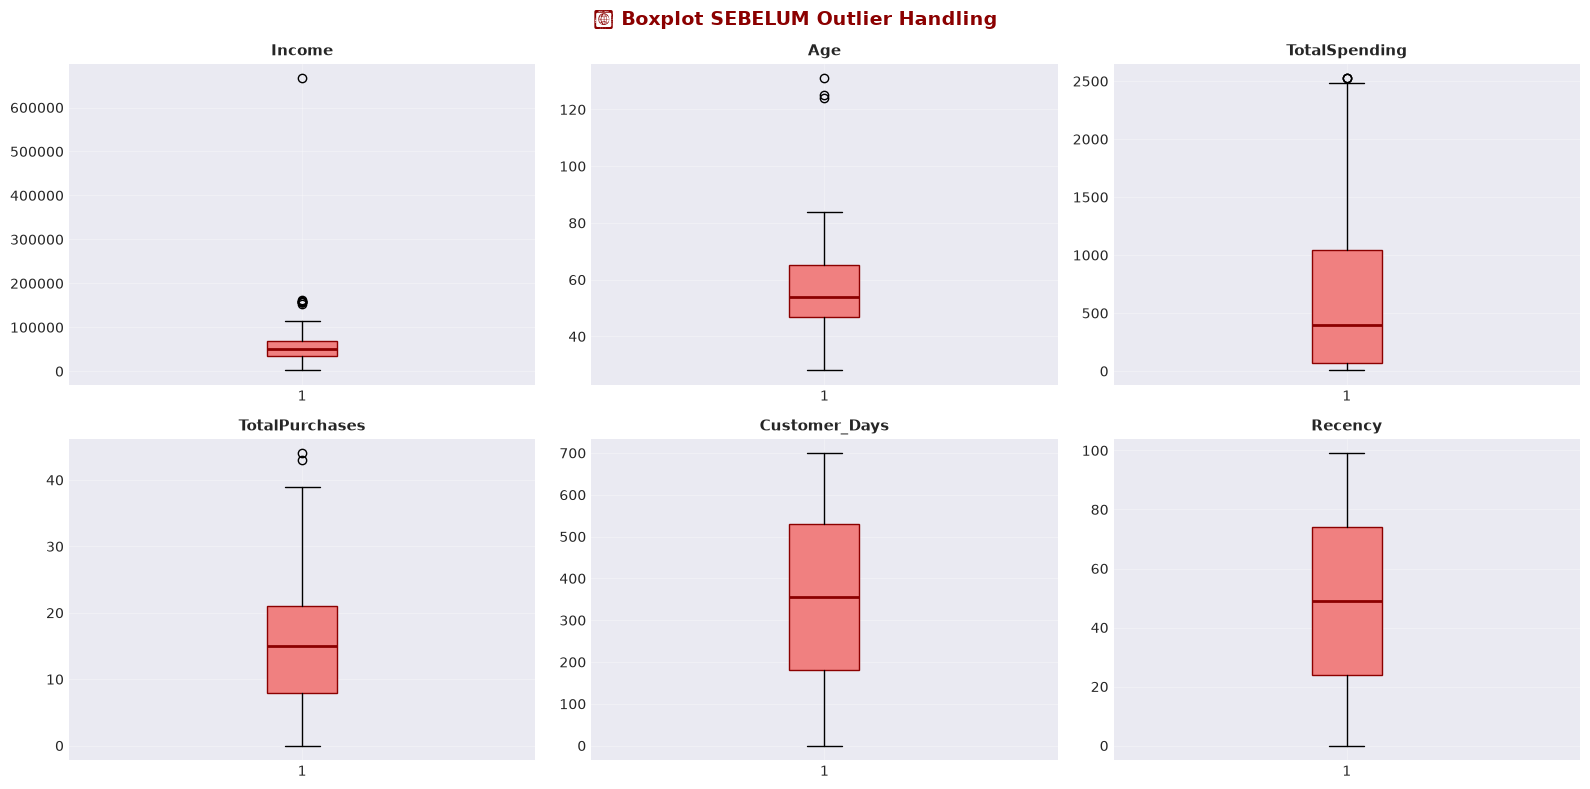

In [24]:
# Visualisasi outlier SEBELUM penanganan
key_features = ['Income', 'Age', 'TotalSpending', 'TotalPurchases', 'Customer_Days', 'Recency']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(key_features):
    axes[i].boxplot(df[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor='lightcoral', color='darkred'),
                    medianprops=dict(color='darkred', linewidth=2))
    axes[i].set_title(f'{col}', fontsize=11, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

plt.suptitle('📦 Boxplot SEBELUM Outlier Handling', fontsize=14, fontweight='bold', color='darkred')
plt.tight_layout()
plt.show()

In [25]:
# ===== IQR CAPPING (WINSORIZING) =====
df_clean = df.copy()
numerical_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()

outlier_summary = []
for col in numerical_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Hitung jumlah outlier
    n_outliers = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()

    # Capping
    df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)

    outlier_summary.append({'Feature': col, 'N_Outliers': n_outliers,
                             'Lower': round(lower_bound, 2), 'Upper': round(upper_bound, 2)})

outlier_df = pd.DataFrame(outlier_summary)
print('📊 Ringkasan Outlier Handling (IQR Capping):')
print(outlier_df[outlier_df['N_Outliers'] > 0].to_string(index=False))
print(f'\n✅ Total outlier di-cap: {outlier_df["N_Outliers"].sum()} nilai')

📊 Ringkasan Outlier Handling (IQR Capping):
              Feature  N_Outliers     Lower     Upper
            Education          54      0.50      4.50
               Income           8 -14525.50 118350.50
    NumWebVisitsMonth           8     -3.00     13.00
             Complain          21      0.00      0.00
                  Age           3     20.00     92.00
        TotalSpending           3  -1396.38   2510.62
       TotalPurchases           2    -11.50     40.50
        TotalChildren          53     -1.50      2.50
TotalCampaignAccepted         463      0.00      0.00

✅ Total outlier di-cap: 615 nilai


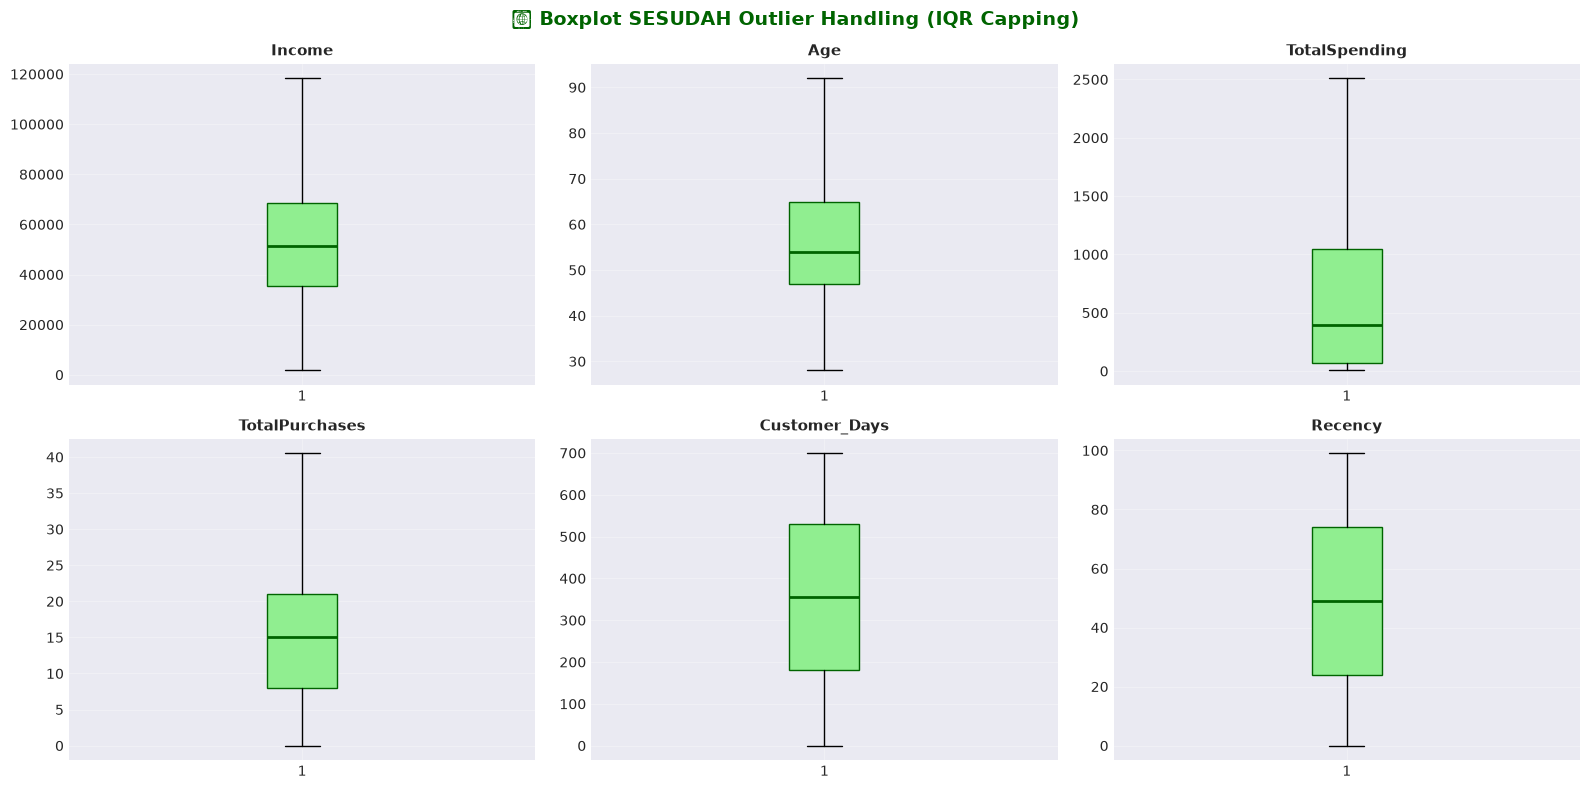

In [26]:
# Visualisasi SESUDAH outlier handling
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(key_features):
    axes[i].boxplot(df_clean[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor='lightgreen', color='darkgreen'),
                    medianprops=dict(color='darkgreen', linewidth=2))
    axes[i].set_title(f'{col}', fontsize=11, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

plt.suptitle('📦 Boxplot SESUDAH Outlier Handling (IQR Capping)', fontsize=14, fontweight='bold', color='darkgreen')
plt.tight_layout()
plt.show()

## 6️⃣ Feature Scaling — StandardScaler
> Hierarchical Clustering menggunakan jarak Euclidean (default) atau jarak lain antar data. StandardScaler memastikan semua fitur berkontribusi secara seimbang tanpa didominasi fitur berskala besar.

In [27]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)
X_scaled_df = pd.DataFrame(X_scaled, columns=df_clean.columns)

# ── Bersihkan NaN/Inf akibat kolom zero-variance ──────────────────────────
# Kolom yang nilainya konstan (std=0) setelah IQR capping → scaler hasilkan NaN
zero_var_cols = X_scaled_df.columns[X_scaled_df.var() == 0].tolist()
if zero_var_cols:
    print(f'⚠️  Kolom zero-variance di-drop setelah scaling: {zero_var_cols}')
    X_scaled_df = X_scaled_df.drop(columns=zero_var_cols)

# Ganti NaN / Inf yang tersisa
X_scaled_df = X_scaled_df.replace([np.inf, -np.inf], np.nan).fillna(0)

print('✅ Feature Scaling (StandardScaler) selesai!')
print(f'Shape: {X_scaled_df.shape}')
print('\nStatistik setelah scaling (seharusnya mean≈0, std≈1):')
print(X_scaled_df.describe().round(3))

⚠️  Kolom zero-variance di-drop setelah scaling: ['Complain', 'TotalCampaignAccepted']
✅ Feature Scaling (StandardScaler) selesai!
Shape: (2240, 10)

Statistik setelah scaling (seharusnya mean≈0, std≈1):
       Education  Marital_Status    Income   Recency  NumWebVisitsMonth  \
count   2240.000        2240.000  2240.000  2240.000           2240.000   
mean       0.000           0.000     0.000    -0.000             -0.000   
std        1.000           1.000     0.995     1.000              1.000   
min       -2.018          -1.542    -2.382    -1.696             -2.257   
25%       -0.483          -1.053    -0.776    -0.867             -0.979   
50%       -0.483           0.415    -0.006    -0.004              0.299   
75%        0.540           0.904     0.780     0.860              0.724   
max        1.563           1.882     3.157     1.723              3.280   

            Age  Customer_Days  TotalSpending  TotalPurchases  TotalChildren  
count  2240.000       2240.000       2240

## 7️⃣ Dendrogram — Menentukan Jumlah Cluster Optimal
> 🌲 **Dendrogram** adalah keunggulan utama Hierarchical Clustering. Ini adalah pohon hierarki yang menunjukkan bagaimana data digabung secara bertahap. Kita potong (cut) dendrogram pada tinggi yang tepat untuk mendapat jumlah cluster optimal.
>
> **Cara membaca:** Garis horizontal panjang = jarak merge yang besar = titik potong yang baik.

In [28]:
# ===== HITUNG LINKAGE MATRIX =====
# Gunakan 'ward' linkage: meminimalkan variance dalam cluster saat merge
# Ward adalah pilihan terbaik untuk data numerik yang sudah di-scale

print(f'Data shape untuk linkage: {X_scaled_df.shape}')
print(f'NaN check: {X_scaled_df.isnull().sum().sum()} | Inf check: {np.isinf(X_scaled_df.values).sum()}')

print('\n⏳ Menghitung linkage matrix (Ward)...')
Z = linkage(X_scaled_df.values, method='ward', metric='euclidean')
print(f'✅ Linkage matrix selesai! Shape: {Z.shape}')
print(f'   Baris = jumlah merge = n-1 = {Z.shape[0]}')
print(f'\n5 baris terakhir linkage matrix (merge terakhir):')
print(pd.DataFrame(Z[-5:], columns=['Cluster1', 'Cluster2', 'Distance', 'N_Elements']).round(4))

Data shape untuk linkage: (2240, 10)
NaN check: 0 | Inf check: 0

⏳ Menghitung linkage matrix (Ward)...
✅ Linkage matrix selesai! Shape: (2239, 4)
   Baris = jumlah merge = n-1 = 2239

5 baris terakhir linkage matrix (merge terakhir):
   Cluster1  Cluster2  Distance  N_Elements
0    4465.0    4473.0   33.2583       670.0
1    4467.0    4471.0   34.5152       745.0
2    4470.0    4475.0   42.9712      1084.0
3    4472.0    4474.0   53.9827      1156.0
4    4476.0    4477.0  101.5776      2240.0


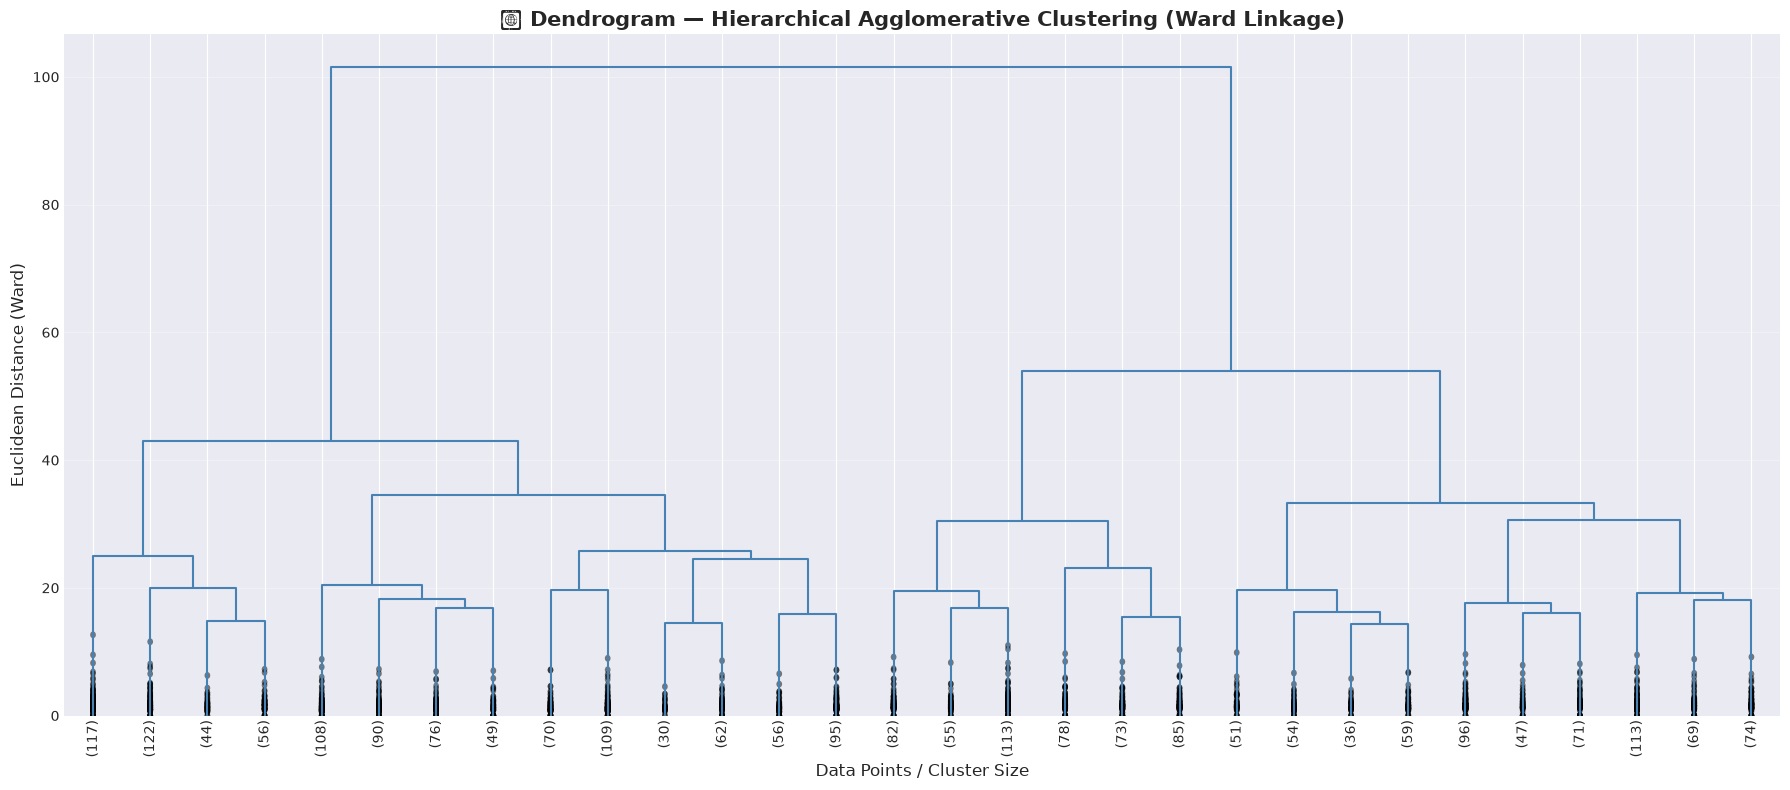

💡 Perhatikan garis horizontal terpanjang yang belum dipotong garis vertikal.
   Garis terpanjang = jarak merge terbesar = titik potong optimal!


In [29]:
# ===== DENDROGRAM (TRUNCATED) =====
plt.figure(figsize=(18, 8))

dendrogram(
    Z,
    truncate_mode='lastp',   # Tampilkan hanya p merge terakhir
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True,
    color_threshold=0,
    above_threshold_color='steelblue'
)

plt.title('🌲 Dendrogram — Hierarchical Agglomerative Clustering (Ward Linkage)',
          fontsize=15, fontweight='bold')
plt.xlabel('Data Points / Cluster Size', fontsize=12)
plt.ylabel('Euclidean Distance (Ward)', fontsize=12)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print('💡 Perhatikan garis horizontal terpanjang yang belum dipotong garis vertikal.')
print('   Garis terpanjang = jarak merge terbesar = titik potong optimal!')

📊 Jarak 15 merge terakhir (dari atas dendrogram):
  Merge 1: distance = 101.5776 | Δ = -47.5948
  Merge 2: distance = 53.9827 | Δ = -11.0115
  Merge 3: distance = 42.9712 | Δ = -8.4560
  Merge 4: distance = 34.5152 | Δ = -1.2569
  Merge 5: distance = 33.2583 | Δ = -2.6055
  Merge 6: distance = 30.6528 | Δ = -0.2267
  Merge 7: distance = 30.4260 | Δ = -4.6562
  Merge 8: distance = 25.7698 | Δ = -0.7346
  Merge 9: distance = 25.0352 | Δ = -0.5628
  Merge 10: distance = 24.4724 | Δ = -1.4449
  Merge 11: distance = 23.0275 | Δ = -2.5136
  Merge 12: distance = 20.5138 | Δ = -0.6029
  Merge 13: distance = 19.9109 | Δ = -0.2161
  Merge 14: distance = 19.6948 | Δ = -0.0761 ← LOMPATAN BESAR!
  Merge 15: distance = 19.6187 | Δ = 0.0000

🏆 Estimasi jumlah cluster optimal: K = 2
   Cut height: 53.4827


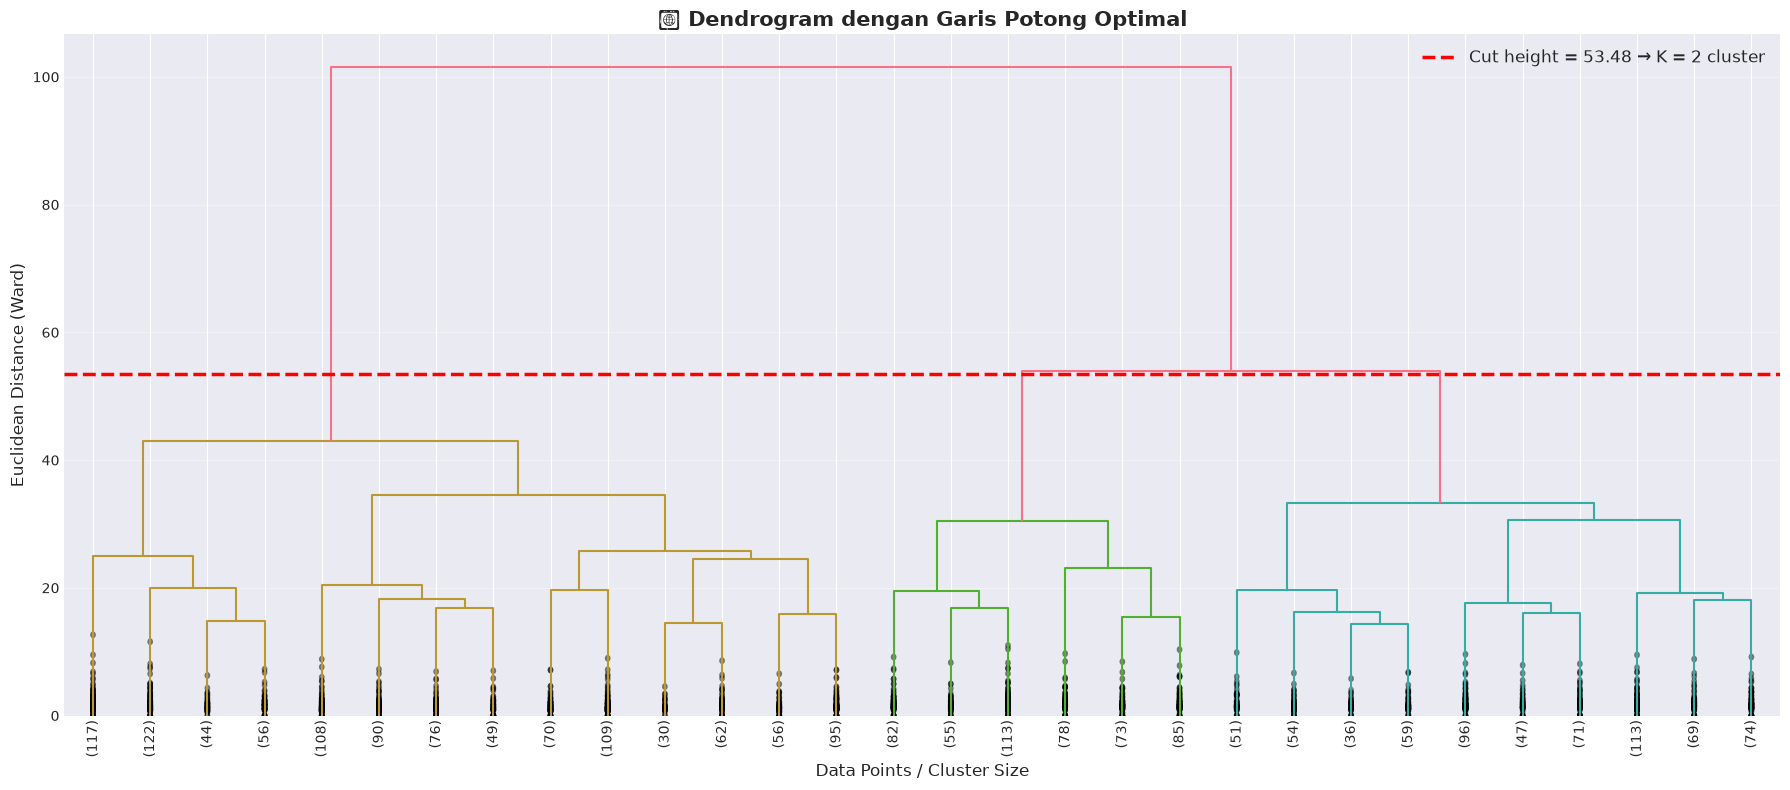

In [30]:
# ===== DENDROGRAM DENGAN GARIS POTONG =====
# Analisis jarak merge untuk menentukan titik potong
last_merges = Z[-15:, 2]  # 15 merge terakhir
merge_diffs = np.diff(last_merges[::-1])  # Selisih jarak

print('📊 Jarak 15 merge terakhir (dari atas dendrogram):')
for i, (dist, diff) in enumerate(zip(last_merges[::-1], np.append(merge_diffs, 0))):
    arrow = ' ← LOMPATAN BESAR!' if diff == max(merge_diffs) else ''
    print(f'  Merge {i+1}: distance = {dist:.4f} | Δ = {diff:.4f}{arrow}')

# Tentukan threshold cut
# Titik potong = setelah lompatan distance terbesar
accel = np.diff(last_merges, 2)[::-1]  # Akselerasi
k_optimal = accel.argmax() + 2
cut_height = last_merges[::-1][k_optimal - 1] - 0.5

print(f'\n🏆 Estimasi jumlah cluster optimal: K = {k_optimal}')
print(f'   Cut height: {cut_height:.4f}')

# Plot dendrogram dengan garis potong
fig, ax = plt.subplots(figsize=(18, 8))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True,
    color_threshold=cut_height,
    ax=ax
)

ax.axhline(y=cut_height, color='red', linestyle='--', linewidth=2.5,
           label=f'Cut height = {cut_height:.2f} → K = {k_optimal} cluster')
ax.set_title('🌲 Dendrogram dengan Garis Potong Optimal', fontsize=15, fontweight='bold')
ax.set_xlabel('Data Points / Cluster Size', fontsize=12)
ax.set_ylabel('Euclidean Distance (Ward)', fontsize=12)
ax.legend(fontsize=12, loc='upper right')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

📊 Evaluasi metrik untuk berbagai K (Agglomerative — Ward):
  K |   Silhouette |  Davies-Bouldin |  Calinski-Harabasz
----------------------------------------------------------
  2 |       0.2043 |          1.7826 |             670.61
  3 |       0.1424 |          2.2240 |             469.55
  4 |       0.1142 |          2.3483 |             378.74
  5 |       0.0971 |          2.3528 |             319.18
  6 |       0.0878 |          2.3581 |             283.59
  7 |       0.0860 |          2.2881 |             257.85
  8 |       0.0879 |          2.3661 |             240.50


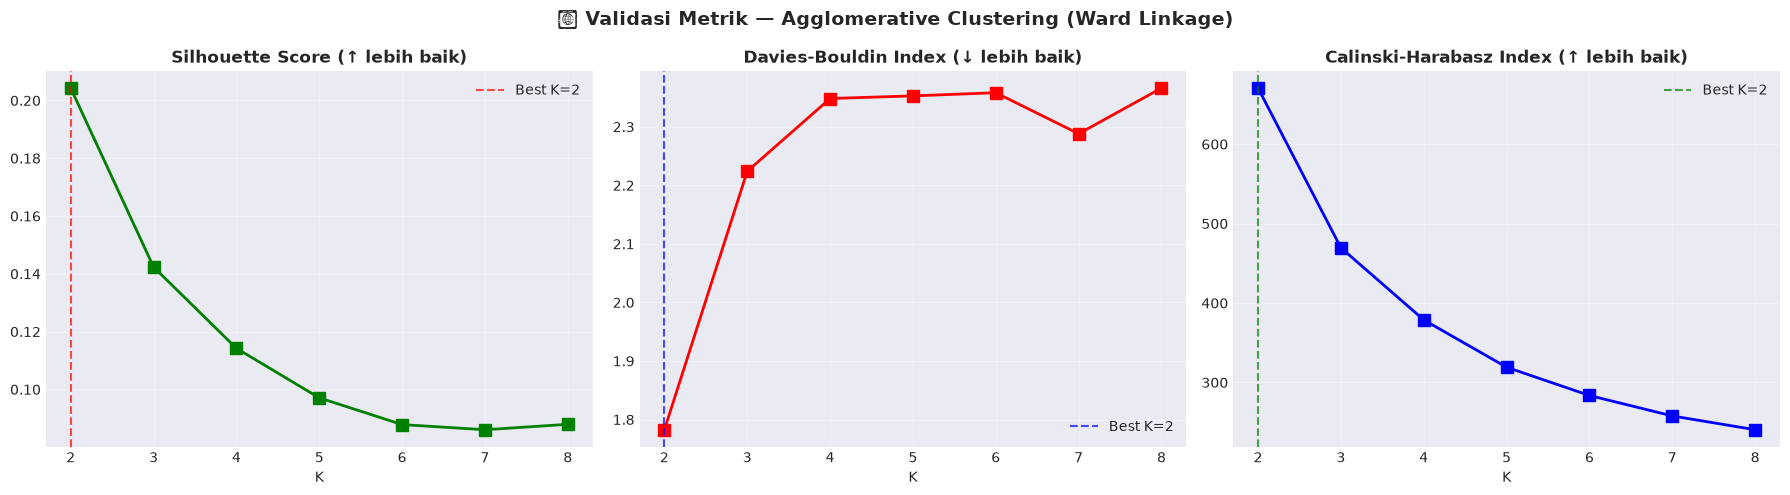


🏆 K optimal berdasarkan Silhouette Score tertinggi: K = 2
   Silhouette Score = 0.2043


In [31]:
# ===== VALIDASI: SILHOUETTE SCORE UNTUK BERBAGAI K =====
# Konfirmasi pilihan K menggunakan Silhouette, Davies-Bouldin, Calinski-Harabasz

K_range = range(2, 9)
sil_scores  = []
db_scores   = []
ch_scores   = []

print('📊 Evaluasi metrik untuk berbagai K (Agglomerative — Ward):')
print(f'{"K":>3} | {"Silhouette":>12} | {"Davies-Bouldin":>15} | {"Calinski-Harabasz":>18}')
print('-' * 58)

for k in K_range:
    model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = model.fit_predict(X_scaled_df)

    sil = silhouette_score(X_scaled_df, labels)
    db  = davies_bouldin_score(X_scaled_df, labels)
    ch  = calinski_harabasz_score(X_scaled_df, labels)

    sil_scores.append(sil)
    db_scores.append(db)
    ch_scores.append(ch)

    print(f'{k:>3} | {sil:>12.4f} | {db:>15.4f} | {ch:>18.2f}')

# Plot metrik
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(K_range, sil_scores, 'gs-', linewidth=2, markersize=9)
axes[0].set_title('Silhouette Score (↑ lebih baik)', fontweight='bold')
axes[0].set_xlabel('K'); axes[0].set_xticks(K_range); axes[0].grid(True, alpha=0.3)
best_k_sil = list(K_range)[sil_scores.index(max(sil_scores))]
axes[0].axvline(x=best_k_sil, color='red', linestyle='--', alpha=0.7, label=f'Best K={best_k_sil}')
axes[0].legend()

axes[1].plot(K_range, db_scores, 'rs-', linewidth=2, markersize=9)
axes[1].set_title('Davies-Bouldin Index (↓ lebih baik)', fontweight='bold')
axes[1].set_xlabel('K'); axes[1].set_xticks(K_range); axes[1].grid(True, alpha=0.3)
best_k_db = list(K_range)[db_scores.index(min(db_scores))]
axes[1].axvline(x=best_k_db, color='blue', linestyle='--', alpha=0.7, label=f'Best K={best_k_db}')
axes[1].legend()

axes[2].plot(K_range, ch_scores, 'bs-', linewidth=2, markersize=9)
axes[2].set_title('Calinski-Harabasz Index (↑ lebih baik)', fontweight='bold')
axes[2].set_xlabel('K'); axes[2].set_xticks(K_range); axes[2].grid(True, alpha=0.3)
best_k_ch = list(K_range)[ch_scores.index(max(ch_scores))]
axes[2].axvline(x=best_k_ch, color='green', linestyle='--', alpha=0.7, label=f'Best K={best_k_ch}')
axes[2].legend()

plt.suptitle('📊 Validasi Metrik — Agglomerative Clustering (Ward Linkage)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Pilih K final berdasarkan Silhouette terbaik
best_k = best_k_sil
print(f'\n🏆 K optimal berdasarkan Silhouette Score tertinggi: K = {best_k}')
print(f'   Silhouette Score = {max(sil_scores):.4f}')

## 8️⃣ Agglomerative Clustering — Model Final
> **Linkage Ward** dipilih karena:
> - Meminimalkan total variance dalam cluster setiap kali merge
> - Menghasilkan cluster yang lebih compact dan seimbang ukurannya
> - Paling cocok untuk data numerik yang sudah di-scale

In [32]:
# ===== AGGLOMERATIVE CLUSTERING FINAL MODEL =====
print(f'Melatih Agglomerative Clustering dengan K={best_k}, linkage=ward...')

agg_model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage='ward',         # Ward: meminimalkan variance saat merge
    metric='euclidean'      # Euclidean distance
)

cluster_labels = agg_model.fit_predict(X_scaled_df)

# Tambahkan label cluster ke dataframe asli
df_result = df.copy()
df_result['Cluster'] = cluster_labels

print(f'✅ Agglomerative Clustering selesai dilatih!')
print(f'\n📊 Distribusi Cluster:')
dist = df_result['Cluster'].value_counts().sort_index()
for cluster, count in dist.items():
    print(f'  Cluster {cluster}: {count} pelanggan ({count/len(df_result)*100:.1f}%)')

print(f'\nTotal: {len(df_result)} pelanggan')

Melatih Agglomerative Clustering dengan K=2, linkage=ward...
✅ Agglomerative Clustering selesai dilatih!

📊 Distribusi Cluster:
  Cluster 0: 1156 pelanggan (51.6%)
  Cluster 1: 1084 pelanggan (48.4%)

Total: 2240 pelanggan


In [33]:
# ===== PERBANDINGAN BERBAGAI LINKAGE =====
# Untuk memastikan Ward adalah pilihan terbaik
linkages = ['ward', 'complete', 'average', 'single']
linkage_metrics = []

print('📊 Perbandingan Silhouette Score berbagai Linkage Method (K={best_k}):')
print(f'{"Linkage":>10} | {"Silhouette":>12} | {"Davies-Bouldin":>15} | {"Calinski-Harabasz":>18}')
print('-' * 62)

for lnk in linkages:
    try:
        m = AgglomerativeClustering(n_clusters=best_k, linkage=lnk)
        lbl = m.fit_predict(X_scaled_df)
        sil = silhouette_score(X_scaled_df, lbl)
        db  = davies_bouldin_score(X_scaled_df, lbl)
        ch  = calinski_harabasz_score(X_scaled_df, lbl)
        print(f'{lnk:>10} | {sil:>12.4f} | {db:>15.4f} | {ch:>18.2f}')
        linkage_metrics.append({'Linkage': lnk, 'Silhouette': sil, 'DB': db, 'CH': ch})
    except Exception as e:
        print(f'{lnk:>10} | Error: {e}')

best_linkage = max(linkage_metrics, key=lambda x: x['Silhouette'])
print(f'\n✅ Linkage terbaik: {best_linkage["Linkage"]} (Silhouette = {best_linkage["Silhouette"]:.4f})')

📊 Perbandingan Silhouette Score berbagai Linkage Method (K={best_k}):
   Linkage |   Silhouette |  Davies-Bouldin |  Calinski-Harabasz
--------------------------------------------------------------
      ward |       0.2043 |          1.7826 |             670.61
  complete |       0.1987 |          1.7766 |             568.58
   average |       0.3242 |          0.9163 |               6.47
    single |       0.2105 |          0.6710 |               2.13

✅ Linkage terbaik: average (Silhouette = 0.3242)


## 9️⃣ Evaluasi Metrik Clustering

In [34]:
# ===== EVALUASI METRIK =====
sil_score_final = silhouette_score(X_scaled_df, cluster_labels)
db_score_final  = davies_bouldin_score(X_scaled_df, cluster_labels)
ch_score_final  = calinski_harabasz_score(X_scaled_df, cluster_labels)

print('=' * 65)
print('  📈 EVALUASI HIERARCHICAL AGGLOMERATIVE CLUSTERING')
print('=' * 65)
print(f'  Jumlah Cluster (K)   : {best_k}')
print(f'  Linkage Method       : Ward')
print(f'  Distance Metric      : Euclidean')
print(f'  Total Data           : {len(df_result)}')
print('-' * 65)
print(f'  ✅ Silhouette Score  : {sil_score_final:.4f}')
print(f'     → Mendekati 1 = cluster semakin terpisah dan padat')
print(f'     → Range: -1 (buruk) hingga 1 (sempurna)')
print()
print(f'  ✅ Davies-Bouldin    : {db_score_final:.4f}')
print(f'     → Semakin kecil = cluster lebih terpisah')
print(f'     → Nilai ideal = 0')
print()
print(f'  ✅ Calinski-Harabasz : {ch_score_final:.4f}')
print(f'     → Semakin besar = cluster lebih padat dan terpisah')
print('=' * 65)

# Simpan untuk perbandingan
hierarchical_metrics = {
    'Model': 'Hierarchical (Agglomerative)',
    'N_Clusters': best_k,
    'Silhouette Score': round(sil_score_final, 4),
    'Davies-Bouldin': round(db_score_final, 4),
    'Calinski-Harabasz': round(ch_score_final, 2)
}
print(f'\n✅ Metrik disimpan: {hierarchical_metrics}')

  📈 EVALUASI HIERARCHICAL AGGLOMERATIVE CLUSTERING
  Jumlah Cluster (K)   : 2
  Linkage Method       : Ward
  Distance Metric      : Euclidean
  Total Data           : 2240
-----------------------------------------------------------------
  ✅ Silhouette Score  : 0.2043
     → Mendekati 1 = cluster semakin terpisah dan padat
     → Range: -1 (buruk) hingga 1 (sempurna)

  ✅ Davies-Bouldin    : 1.7826
     → Semakin kecil = cluster lebih terpisah
     → Nilai ideal = 0

  ✅ Calinski-Harabasz : 670.6071
     → Semakin besar = cluster lebih padat dan terpisah

✅ Metrik disimpan: {'Model': 'Hierarchical (Agglomerative)', 'N_Clusters': 2, 'Silhouette Score': 0.2043, 'Davies-Bouldin': 1.7826, 'Calinski-Harabasz': 670.61}


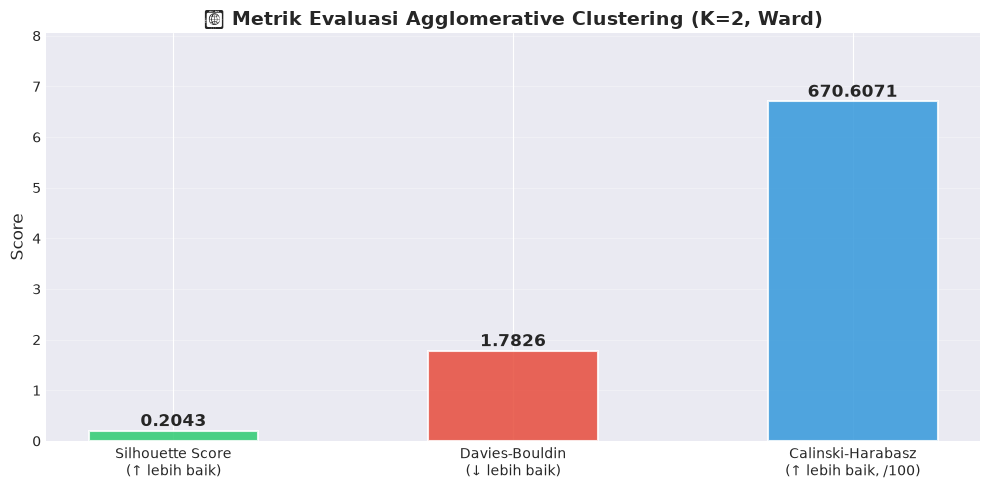

In [35]:
# Visualisasi metrik evaluasi
metrics_names = ['Silhouette Score\n(↑ lebih baik)', 'Davies-Bouldin\n(↓ lebih baik)', 'Calinski-Harabasz\n(↑ lebih baik, /100)']
metrics_values = [sil_score_final, db_score_final, ch_score_final / 100]
colors_bar = ['#2ecc71', '#e74c3c', '#3498db']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(metrics_names, metrics_values, color=colors_bar, alpha=0.85,
              edgecolor='white', linewidth=1.5, width=0.5)

for bar, val, orig in zip(bars, metrics_values, [sil_score_final, db_score_final, ch_score_final]):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
            f'{orig:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_title(f'📊 Metrik Evaluasi Agglomerative Clustering (K={best_k}, Ward)', fontsize=14, fontweight='bold')
ax.set_ylabel('Score', fontsize=12)
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, max(metrics_values) * 1.2)
plt.tight_layout()
plt.show()

## 🔟 Visualisasi Cluster — PCA 2D

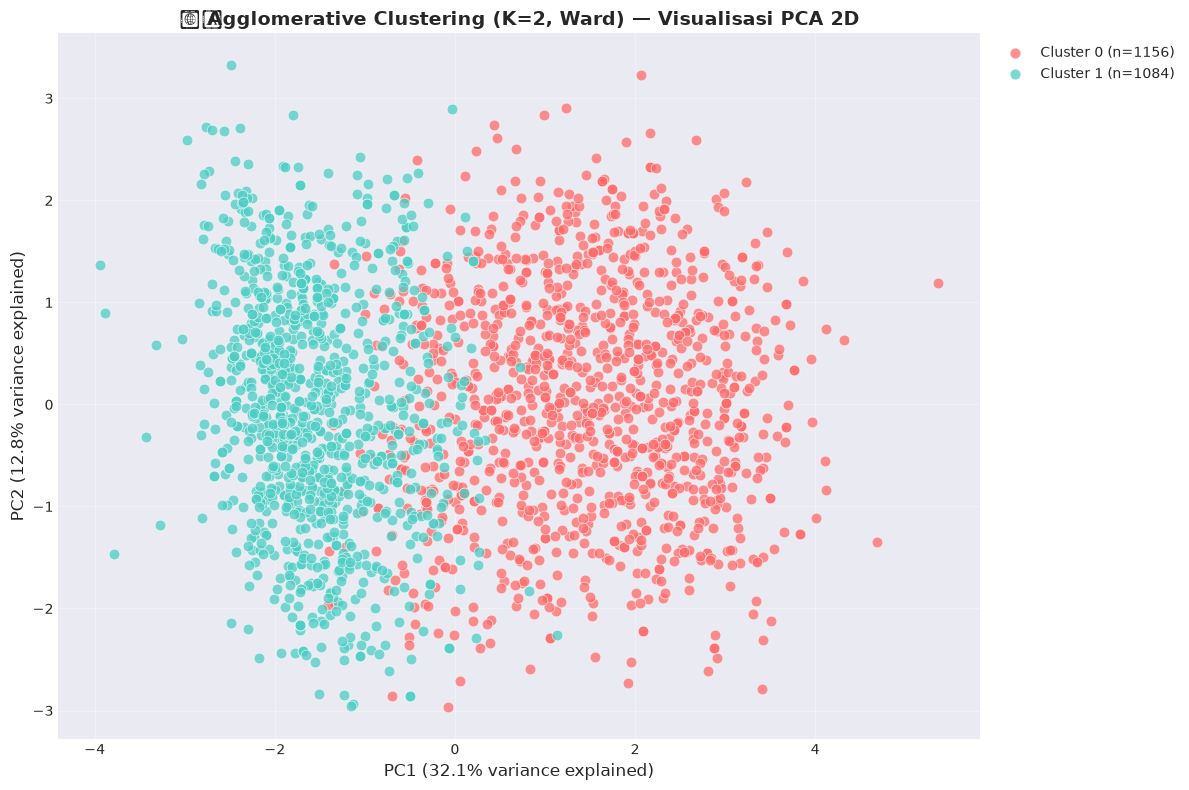

Total variance explained oleh 2 PC: 44.96%


In [36]:
# ===== VISUALISASI PCA 2D =====
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled_df)

cluster_colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7', '#DDA0DD', '#F8B4D9', '#AED6F1']

plt.figure(figsize=(12, 8))
for cluster in range(best_k):
    mask = cluster_labels == cluster
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=cluster_colors[cluster], label=f'Cluster {cluster} (n={mask.sum()})',
                s=60, alpha=0.75, edgecolors='white', linewidth=0.5)

plt.title(f'🗺️ Agglomerative Clustering (K={best_k}, Ward) — Visualisasi PCA 2D', fontsize=14, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance explained)', fontsize=12)
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance explained)', fontsize=12)
plt.legend(fontsize=10, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

total_var = sum(pca.explained_variance_ratio_) * 100
print(f'Total variance explained oleh 2 PC: {total_var:.2f}%')

In [37]:
# ===== CLUSTER PROFILING =====
profiling_features = ['Income', 'Age', 'TotalSpending', 'TotalPurchases',
                      'TotalChildren', 'TotalCampaignAccepted', 'Customer_Days', 'Recency', 'NumWebVisitsMonth']

cluster_profile = df_result.groupby('Cluster')[profiling_features].mean().round(2)
print('📊 CLUSTER PROFILING — AGGLOMERATIVE CLUSTERING')
print('=' * 80)
print(cluster_profile.T)
print('\n')
print(cluster_profile)

📊 CLUSTER PROFILING — AGGLOMERATIVE CLUSTERING
Cluster                       0         1
Income                 68500.17  34902.72
Age                       57.84     52.37
TotalSpending           1052.15    129.80
TotalPurchases            20.44      8.91
TotalChildren              0.64      1.28
TotalCampaignAccepted      0.49      0.10
Customer_Days            366.80    339.48
Recency                   48.40     49.86
NumWebVisitsMonth          4.07      6.65


           Income    Age  TotalSpending  TotalPurchases  TotalChildren  \
Cluster                                                                  
0        68500.17  57.84        1052.15           20.44           0.64   
1        34902.72  52.37         129.80            8.91           1.28   

         TotalCampaignAccepted  Customer_Days  Recency  NumWebVisitsMonth  
Cluster                                                                    
0                         0.49         366.80    48.40               4.07  
1     

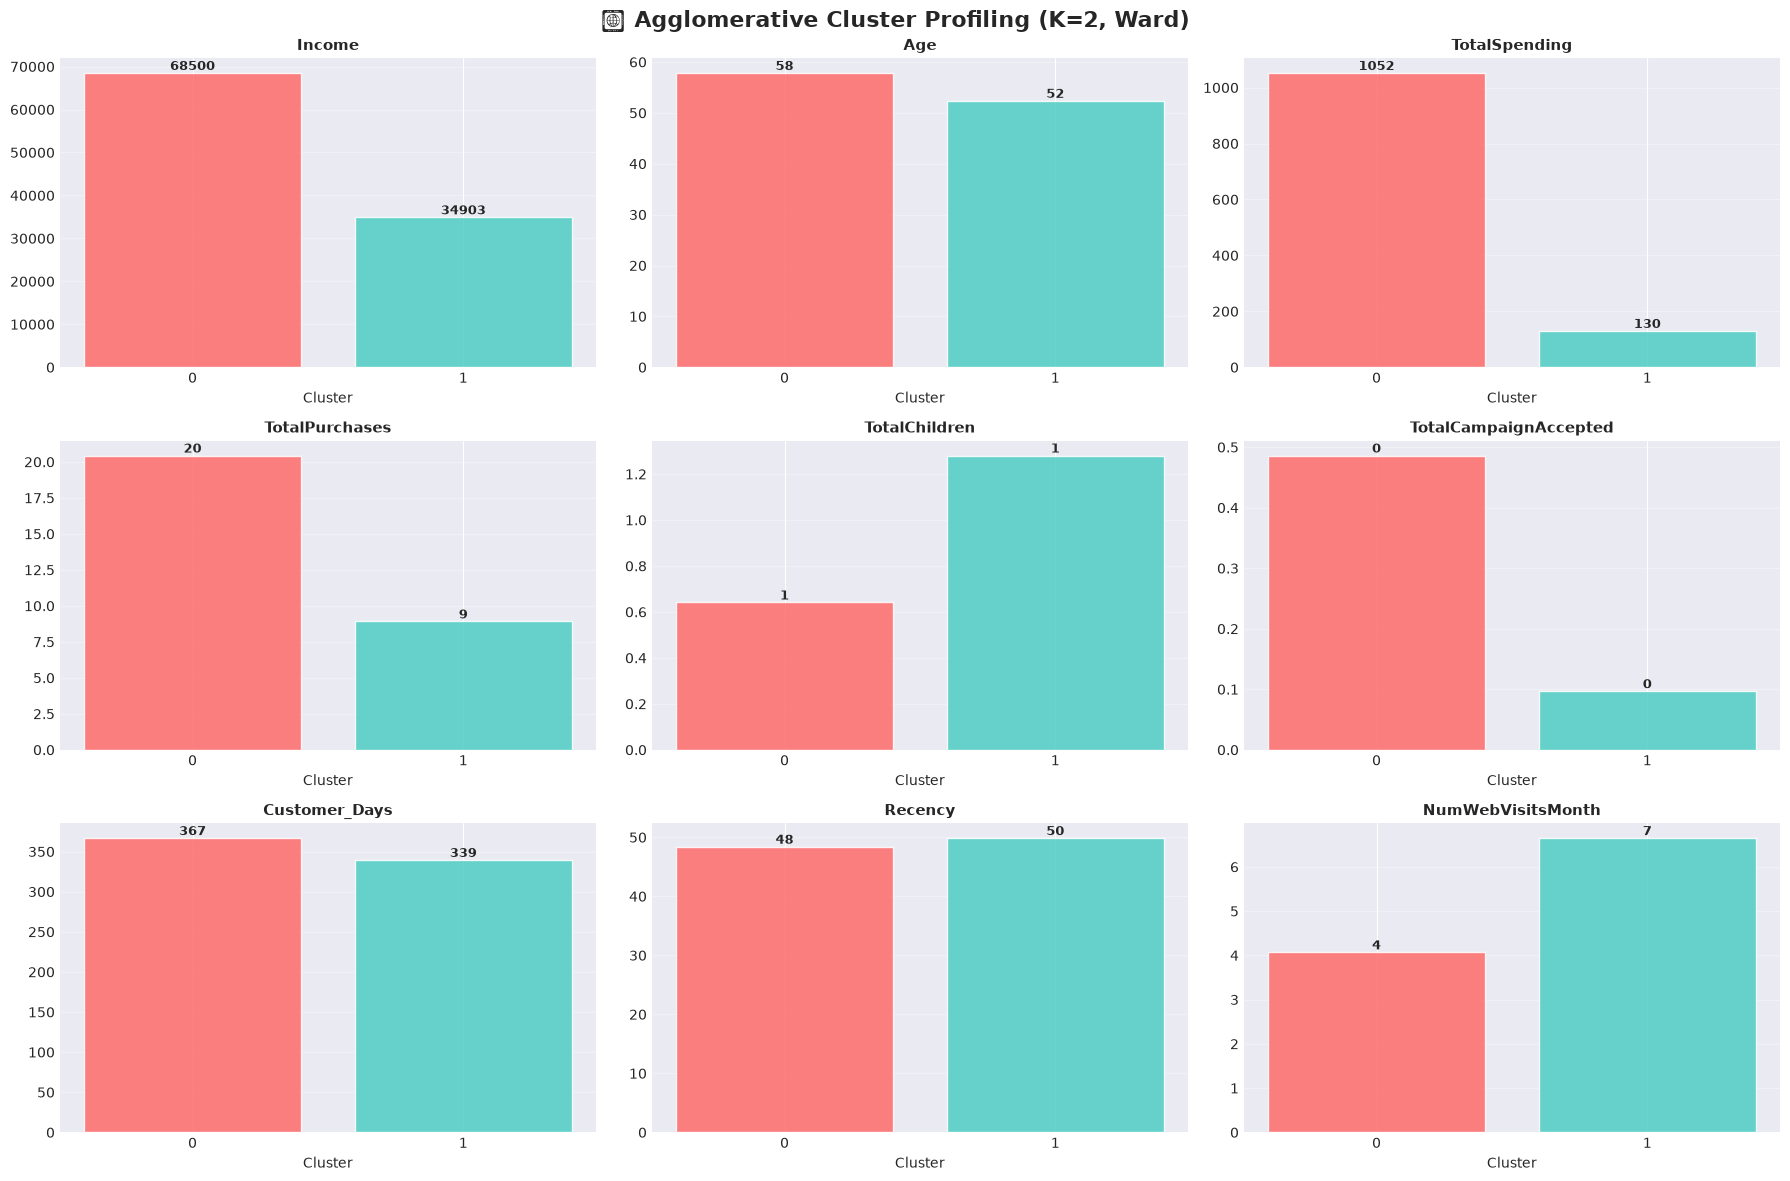

In [38]:
# Visualisasi profil cluster per fitur
n_feat = len(profiling_features)
n_cols_fig = 3
n_rows_fig = (n_feat + n_cols_fig - 1) // n_cols_fig

fig, axes = plt.subplots(n_rows_fig, n_cols_fig, figsize=(18, n_rows_fig * 4))
axes = axes.flatten()

for i, feat in enumerate(profiling_features):
    cluster_means = df_result.groupby('Cluster')[feat].mean()
    bars = axes[i].bar(cluster_means.index.astype(str),
                       cluster_means.values,
                       color=[cluster_colors[j] for j in cluster_means.index],
                       alpha=0.85, edgecolor='white', linewidth=1)
    axes[i].set_title(f'{feat}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Cluster')
    axes[i].grid(True, alpha=0.3, axis='y')
    for bar, val in zip(bars, cluster_means.values):
        axes[i].text(bar.get_x() + bar.get_width()/2., bar.get_height(),
                     f'{val:.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f'📊 Agglomerative Cluster Profiling (K={best_k}, Ward)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

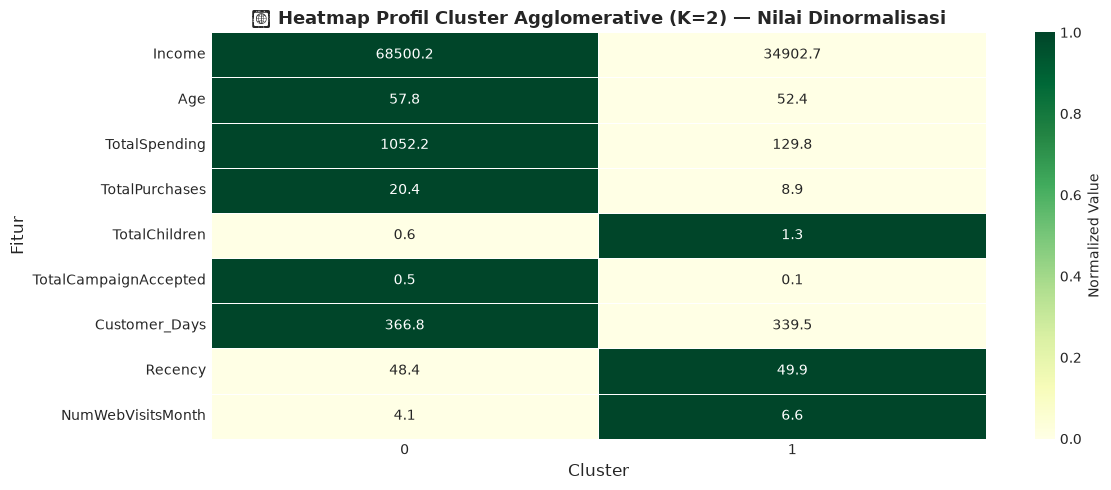

In [39]:
# Heatmap profil cluster (normalized)
profile_norm = (cluster_profile - cluster_profile.min()) / (cluster_profile.max() - cluster_profile.min())

plt.figure(figsize=(12, 5))
sns.heatmap(profile_norm.T, annot=cluster_profile.T.round(1), fmt='g',
            cmap='YlGn', linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Normalized Value'})
plt.title(f'🔥 Heatmap Profil Cluster Agglomerative (K={best_k}) — Nilai Dinormalisasi', fontsize=13, fontweight='bold')
plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Fitur', fontsize=12)
plt.tight_layout()
plt.show()

## 1️⃣1️⃣ Perbandingan K-Means vs Hierarchical Clustering
> **Catatan:** Metrik K-Means di bawah adalah nilai referensi yang perlu diisi manual dari file `sentimen.ipynb` setelah menjalankan kedua notebook.

In [40]:
# ===== PERBANDINGAN MODEL =====
# ⚠️ Isi nilai K-Means dari hasil sentimen.ipynb
# Ganti nilai di bawah sesuai output dari sentimen.ipynb

comparison_data = {
    'Metrik': ['Silhouette Score ↑', 'Davies-Bouldin ↓', 'Calinski-Harabasz ↑'],
    'K-Means (dari sentimen.ipynb)': [
        '(isi dari sentimen.ipynb)',    # ← Ganti dengan nilai aktual
        '(isi dari sentimen.ipynb)',    # ← Ganti dengan nilai aktual
        '(isi dari sentimen.ipynb)'     # ← Ganti dengan nilai aktual
    ],
    'Hierarchical Agglomerative': [
        round(sil_score_final, 4),
        round(db_score_final, 4),
        round(ch_score_final, 2)
    ]
}

df_comparison = pd.DataFrame(comparison_data)
print('📊 TABEL PERBANDINGAN MODEL CLUSTERING')
print('=' * 75)
print(df_comparison.to_string(index=False))
print('=' * 75)
print()
print('📝 Keterangan Metrik:')
print('  • Silhouette Score : Range -1 s/d 1. Semakin TINGGI semakin baik.')
print('  • Davies-Bouldin   : Range 0 s/d ∞. Semakin RENDAH semakin baik.')
print('  • Calinski-Harabasz: Range 0 s/d ∞. Semakin TINGGI semakin baik.')

📊 TABEL PERBANDINGAN MODEL CLUSTERING
             Metrik K-Means (dari sentimen.ipynb)  Hierarchical Agglomerative
 Silhouette Score ↑     (isi dari sentimen.ipynb)                      0.2043
   Davies-Bouldin ↓     (isi dari sentimen.ipynb)                      1.7826
Calinski-Harabasz ↑     (isi dari sentimen.ipynb)                    670.6100

📝 Keterangan Metrik:
  • Silhouette Score : Range -1 s/d 1. Semakin TINGGI semakin baik.
  • Davies-Bouldin   : Range 0 s/d ∞. Semakin RENDAH semakin baik.
  • Calinski-Harabasz: Range 0 s/d ∞. Semakin TINGGI semakin baik.


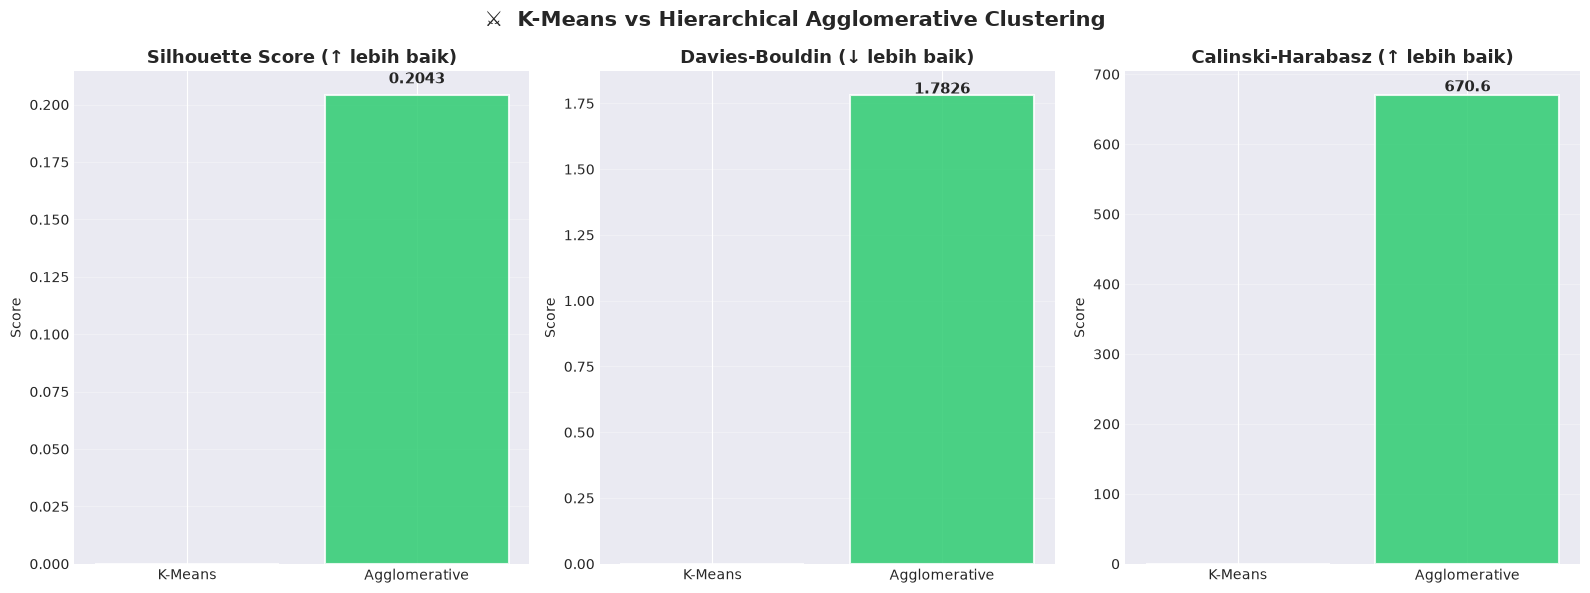

💡 Isi nilai kmeans_sil, kmeans_db, kmeans_ch dari output sentimen.ipynb untuk melihat perbandingan lengkap!


In [41]:
# ===== VISUALISASI PERBANDINGAN METRIK =====
# Hanya menampilkan metrik Hierarchical (K-Means perlu diisi manual)
# Gunakan cell ini setelah mengisi nilai K-Means di atas

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# Contoh: Isi dengan nilai K-Means setelah menjalankan sentimen.ipynb
# Ganti 0 dengan nilai aktual dari K-Means
kmeans_sil = 0      # ← Ganti dengan nilai aktual
kmeans_db  = 0      # ← Ganti dengan nilai aktual
kmeans_ch  = 0      # ← Ganti dengan nilai aktual

models = ['K-Means', 'Agglomerative']
silhouettes = [kmeans_sil, sil_score_final]
dbs = [kmeans_db, db_score_final]
chs = [kmeans_ch, ch_score_final]
bar_colors = ['#3498db', '#2ecc71']

# Silhouette
bars0 = axes[0].bar(models, silhouettes, color=bar_colors, alpha=0.85, edgecolor='white', linewidth=1.5)
axes[0].set_title('Silhouette Score (↑ lebih baik)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Score')
axes[0].grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars0, silhouettes):
    if val > 0:
        axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
                     f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')

# Davies-Bouldin
bars1 = axes[1].bar(models, dbs, color=bar_colors, alpha=0.85, edgecolor='white', linewidth=1.5)
axes[1].set_title('Davies-Bouldin (↓ lebih baik)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Score')
axes[1].grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars1, dbs):
    if val > 0:
        axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
                     f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')

# Calinski-Harabasz
bars2 = axes[2].bar(models, chs, color=bar_colors, alpha=0.85, edgecolor='white', linewidth=1.5)
axes[2].set_title('Calinski-Harabasz (↑ lebih baik)', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Score')
axes[2].grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars2, chs):
    if val > 0:
        axes[2].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 5,
                     f'{val:.1f}', ha='center', fontsize=11, fontweight='bold')

plt.suptitle('⚔️  K-Means vs Hierarchical Agglomerative Clustering', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()
print('💡 Isi nilai kmeans_sil, kmeans_db, kmeans_ch dari output sentimen.ipynb untuk melihat perbandingan lengkap!')

In [42]:
# ===== RINGKASAN AKHIR =====
print('🎯 RINGKASAN HIERARCHICAL AGGLOMERATIVE CLUSTERING')
print('=' * 65)
print(f'  Dataset          : Marketing Campaign (marketing_campaign.csv)')
print(f'  Total Pelanggan  : {len(df_result)}')
print(f'  Jumlah Fitur     : {X_scaled_df.shape[1]}')
print()
print(f'  ⚙️  Konfigurasi Model:')
print(f'  Algorithm        : Agglomerative Clustering')
print(f'  Linkage          : Ward (meminimalkan variance)')
print(f'  Distance Metric  : Euclidean')
print(f'  Jumlah Cluster K : {best_k}')
print()
print(f'  📈 Evaluasi Metrik:')
print(f'  Silhouette Score : {sil_score_final:.4f}')
print(f'  Davies-Bouldin   : {db_score_final:.4f}')
print(f'  Calinski-Harabasz: {ch_score_final:.2f}')
print()
print(f'  📦 Distribusi Cluster:')
for cluster, count in df_result['Cluster'].value_counts().sort_index().items():
    print(f'  Cluster {cluster}: {count:>4} pelanggan ({count/len(df_result)*100:.1f}%)')
print('=' * 65)
print('\n✅ Hierarchical Clustering selesai!')
print('📁 Bandingkan dengan K-Means di file sentimen.ipynb.')

🎯 RINGKASAN HIERARCHICAL AGGLOMERATIVE CLUSTERING
  Dataset          : Marketing Campaign (marketing_campaign.csv)
  Total Pelanggan  : 2240
  Jumlah Fitur     : 10

  ⚙️  Konfigurasi Model:
  Algorithm        : Agglomerative Clustering
  Linkage          : Ward (meminimalkan variance)
  Distance Metric  : Euclidean
  Jumlah Cluster K : 2

  📈 Evaluasi Metrik:
  Silhouette Score : 0.2043
  Davies-Bouldin   : 1.7826
  Calinski-Harabasz: 670.61

  📦 Distribusi Cluster:
  Cluster 0: 1156 pelanggan (51.6%)
  Cluster 1: 1084 pelanggan (48.4%)

✅ Hierarchical Clustering selesai!
📁 Bandingkan dengan K-Means di file sentimen.ipynb.
